# 🧪 Zero to Fine-Tuned with an Invented Dataset

## Ellora Recipe #7: From a Plain-Language Request to a LoRA Adapter

This notebook goes from a one-sentence description of the data you want to a fine-tuned LoRA adapter, using only open tools. It is an open counterpart to the "Zero to Fine-Tuned Model" walkthrough from Adaption Labs, which pairs their Invent a Dataset tool with AutoScientist.

**Step 1, invent the data.** [DataInventor](https://huggingface.co/spaces/LocalLLaMA/data-inventor) is an open-source recreation of the Invent a Dataset workflow. You describe the dataset in plain words, it drafts a blueprint (topics, personas, question shapes), samples unique combinations, writes one message and one reply per combination, and filters out cut-off, degenerate and near-duplicate rows. It works with any OpenAI-compatible endpoint. DataInventor is not affiliated with Adaption Labs.

**Step 2, fine-tune.** A LoRA adapter is trained with PEFT and the Transformers `Trainer` on the invented rows, then compared with the base model on held-out rows it never saw.

### Architecture:
- **Dataset:** [LocalLLaMA/datainventor-support-banking](https://huggingface.co/datasets/LocalLLaMA/datainventor-support-banking), 200 synthetic banking support conversations (card activation, card blocking, mortgages, verification, escalation) written by DataInventor from the request *"Dataset of customer service responses guiding users through credit card activation, blocking, and mortgage inquiries."*
- **Base Model:** Qwen/Qwen2.5-1.5B-Instruct (fits a free 16GB T4 in fp16)
- **Training Method:** Supervised LoRA fine-tuning, loss on the reply tokens only
- **Evaluation:** Held-out reply loss and perplexity, ROUGE-L and embedding similarity against the reference replies, side-by-side examples, and an optional LLM judge
- **Runtime:** about 15 minutes on a single T4 (Colab free tier; set Runtime > Change runtime type > T4 GPU)

### What to expect
With 170 training rows the adapter mostly learns the *style* of the dataset: the length, structure and tone of a banking support reply. It does not learn new banking facts, and the rows were written by a model and never checked by a person, so the adapter inherits that model's habits and any mistakes in the data. Read the side-by-side examples, not just the numbers.

## 📦 Setup and Installation

In [1]:
# Install required packages (torch and transformers are left as provided by Colab)
!pip install -q "peft>=0.11.0" "accelerate>=0.30.0" "datasets>=2.18.0"
!pip install -q rouge_score sentence-transformers
!pip install -q matplotlib pandas tqdm
# Colab ships an old torchao that recent peft rejects; peft does not need it here
!pip uninstall -y -q torchao

In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    TrainingArguments,
    Trainer,
)
from peft import LoraConfig, get_peft_model, PeftModel
from datasets import load_dataset
from tqdm.auto import tqdm
import json
import math
import os
import random
import time
from typing import List, Dict
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

TIMINGS = {}
T_START = time.time()

print(f"PyTorch version: {torch.__version__}")
import transformers, peft
print(f"Transformers version: {transformers.__version__}, PEFT version: {peft.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} (compute capability {torch.cuda.get_device_capability(0)})")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch version: 2.11.0+cu130
Transformers version: 5.20.2, PEFT version: 0.21.2
CUDA available: True
GPU: Tesla T4 (compute capability (7, 5))
GPU memory: 15.6 GB


## ⚙️ Configuration

In [3]:
# Experiment Configuration
CONFIG = {
    # Data
    "dataset_name": "LocalLLaMA/datainventor-support-banking",
    "num_eval_samples": 30,          # held out from the 200 rows, never trained on
    "split_seed": 42,

    # Model settings
    "model_name": "Qwen/Qwen2.5-1.5B-Instruct",
    "cache_dir": "./models",
    "max_seq_length": 2048,          # longest prompt + reply in the dataset is about 1,500 tokens

    # LoRA configuration
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],

    # Training settings
    "num_epochs": 2,
    "batch_size": 2,
    "gradient_accumulation_steps": 4,  # effective batch of 8
    "learning_rate": 2e-4,
    "warmup_ratio": 0.1,
    "weight_decay": 0.0,
    "lr_scheduler": "cosine",
    "logging_steps": 5,

    # Evaluation (identical settings for the base model and the adapter)
    "max_new_tokens": 768,
    "gen_batch_size": 10,
    "repetition_penalty": 1.05,
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",

    # Output
    "output_dir": "./banking_support_lora",
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(json.dumps(CONFIG, indent=2))

{
  "dataset_name": "LocalLLaMA/datainventor-support-banking",
  "num_eval_samples": 30,
  "split_seed": 42,
  "model_name": "Qwen/Qwen2.5-1.5B-Instruct",
  "cache_dir": "./models",
  "max_seq_length": 2048,
  "lora_r": 16,
  "lora_alpha": 32,
  "lora_dropout": 0.05,
  "target_modules": [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
  ],
  "num_epochs": 2,
  "batch_size": 2,
  "gradient_accumulation_steps": 4,
  "learning_rate": 0.0002,
  "warmup_ratio": 0.1,
  "weight_decay": 0.0,
  "lr_scheduler": "cosine",
  "logging_steps": 5,
  "max_new_tokens": 768,
  "gen_batch_size": 10,
  "repetition_penalty": 1.05,
  "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
  "output_dir": "./banking_support_lora"
}


## 🧪 Optional: Invent Your Own Rows with DataInventor

This recipe trains on a dataset DataInventor already wrote, so this cell is **skipped by default**. Set `RUN_INVENT = True` to write your own rows instead.

Two ways to run it:
- **The hosted app.** Open the [DataInventor Space](https://huggingface.co/spaces/LocalLLaMA/data-inventor), describe the data, preview the blueprint, and download the rows as JSONL. The cell below calls the same app over HTTP (up to 200 rows per run, and the host runs at most two jobs at a time).
- **Your own endpoint.** Clone the Space and run the app yourself against any OpenAI-compatible server (vLLM, SGLang, Ollama or a hosted API): `pip install -r requirements.txt`, then `cd app && DI_API_KEY=... DI_BASE_URL=... DI_MODEL=... uvicorn main:app --port 7860`, and point `DI_URL` below at `http://localhost:7860`.

The `datainventor` pip package and CLI (`datainventor init / preview / run`) cover the other mode of the app, curating a pretraining corpus, so row invention goes through the app API shown here.

The downloaded file has the same `prompt` / `completion` columns as the showcase dataset, so the rest of the notebook works unchanged if you set `CONFIG["dataset_name"]` to the local JSONL path.

In [4]:
RUN_INVENT = False   # set True to invent your own rows (needs network access to the app)

DI_URL = "https://codelion-data-inventor.hf.space"   # the app behind the LocalLLaMA/data-inventor Space, or your own host
INVENT_SPEC = {
    "format": "instruction",          # or "preference" for chosen / rejected pairs
    "request": "Dataset of customer service responses guiding users through credit card activation, blocking, and mortgage inquiries.",
    "languages": ["English"],
    "domains": [],
    "subdomains": [],
    "constraints": "",
    "rows": 200,
}

if RUN_INVENT:
    import requests
    job_id = requests.post(f"{DI_URL}/api/jobs", json=INVENT_SPEC, timeout=60).json()["id"]
    print(f"Started DataInventor job {job_id}")
    while True:
        st = requests.get(f"{DI_URL}/api/jobs/{job_id}", timeout=60).json()
        print(f"  {st['state']}: {st['count']}/{st['target']} rows, rejected {st['rejected']}")
        if st["state"] in ("done", "stopped", "failed"):
            break
        time.sleep(20)
    body = requests.get(f"{DI_URL}/api/jobs/{job_id}/download", params={"format": "jsonl"}, timeout=120).text
    with open("invented_rows.jsonl", "w") as f:
        f.write(body)
    CONFIG["dataset_name"] = "invented_rows.jsonl"
    print(f"Saved {len(body.splitlines())} rows to invented_rows.jsonl")
else:
    print("⏭️ Skipping row invention, using the published DataInventor dataset:", CONFIG["dataset_name"])

⏭️ Skipping row invention, using the published DataInventor dataset: LocalLLaMA/datainventor-support-banking


## 📊 Load the Invented Dataset

In [5]:
if CONFIG["dataset_name"].endswith(".jsonl"):
    raw = load_dataset("json", data_files=CONFIG["dataset_name"])["train"]
else:
    raw = load_dataset(CONFIG["dataset_name"])["train"]

print(raw)
df = raw.to_pandas()
print("\nColumns:", list(df.columns))
print("\nRows per area:")
print(df["area"].value_counts().to_string())
print("\nRows per question shape:")
print(df["shape"].value_counts().to_string())
print(f"\nAverage words per prompt: {df['prompt'].str.split().str.len().mean():.1f}")
print(f"Average words per completion: {df['completion'].str.split().str.len().mean():.1f}")

ex = raw[0]
print("\n--- Example row ---")
print("PERSONA:", ex["persona"], "| SHAPE:", ex["shape"], "| DIFFICULTY:", ex["difficulty"])
print("PROMPT:", ex["prompt"])
print("COMPLETION:", ex["completion"][:600], "...")

Dataset({
    features: ['prompt', 'completion', 'area', 'subtopic', 'topic', 'persona', 'shape', 'difficulty', 'language'],
    num_rows: 200
})

Columns: ['prompt', 'completion', 'area', 'subtopic', 'topic', 'persona', 'shape', 'difficulty', 'language']

Rows per area:
area
Mortgage Inquiries        39
Credit Card Blocking      36
Credit Card Activation    34
Administrative Tasks      32
Support Escalation        32
Customer Verification     27

Rows per question shape:
shape
With constraints           38
Comparison                 37
Detailed brief             36
Short ask                  32
Follow-up                  29
With a concrete example    28

Average words per prompt: 55.4
Average words per completion: 294.5

--- Example row ---
PERSONA: UX Researcher | SHAPE: Short ask | DIFFICULTY: intermediate
PROMPT: Can you draft a few conversational prompts for the app's biometric setup flow that don't sound too robotic? I need the wording to clearly explain why we're asking for Face

In [6]:
# Fixed-seed split: the held-out rows are never seen during training
split = raw.train_test_split(test_size=CONFIG["num_eval_samples"], seed=CONFIG["split_seed"])
train_rows = split["train"]
eval_rows = split["test"]
print(f"✅ Train rows: {len(train_rows)} | Held-out rows: {len(eval_rows)}")
print("Held-out areas:", dict(pd.Series(eval_rows["area"]).value_counts()))

✅ Train rows: 170 | Held-out rows: 30
Held-out areas: {'Administrative Tasks': np.int64(7), 'Credit Card Activation': np.int64(7), 'Credit Card Blocking': np.int64(6), 'Support Escalation': np.int64(4), 'Customer Verification': np.int64(3), 'Mortgage Inquiries': np.int64(3)}


## 🤖 Model Loading

In [7]:
def load_base_model(model_name: str, cache_dir: str):
    # Load the base model in fp16 on GPU (fp32 on CPU)
    print(f"📚 Loading base model: {model_name}...")
    tokenizer = AutoTokenizer.from_pretrained(model_name, cache_dir=cache_dir)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=DTYPE,
        cache_dir=cache_dir,
    ).to(DEVICE)
    print(f"✅ Base model loaded: {model.num_parameters():,} parameters")
    return model, tokenizer

t0 = time.time()
model, tokenizer = load_base_model(CONFIG["model_name"], CONFIG["cache_dir"])
TIMINGS["load_model_s"] = round(time.time() - t0, 1)

📚 Loading base model: Qwen/Qwen2.5-1.5B-Instruct...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

✅ Base model loaded: 1,543,714,304 parameters


## 🧩 Chat Formatting

Each row becomes a two-turn chat in the model's own chat template. The loss is computed on the reply tokens only, so the adapter learns how to answer rather than how to ask.

In [8]:
def build_messages(prompt: str) -> List[Dict]:
    return [{"role": "user", "content": prompt}]

def prompt_text(prompt: str) -> str:
    return tokenizer.apply_chat_template(build_messages(prompt), tokenize=False, add_generation_prompt=True)

def encode_example(prompt: str, completion: str) -> Dict:
    # Token ids for prompt + reply, with labels masked (-100) on the prompt part
    p_ids = tokenizer(prompt_text(prompt), add_special_tokens=False)["input_ids"]
    c_ids = tokenizer(completion + tokenizer.eos_token, add_special_tokens=False)["input_ids"]
    ids = (p_ids + c_ids)[: CONFIG["max_seq_length"]]
    labels = ([-100] * len(p_ids) + c_ids)[: CONFIG["max_seq_length"]]
    return {"input_ids": ids, "labels": labels}

def collate(batch: List[Dict]) -> Dict:
    width = max(len(b["input_ids"]) for b in batch)
    ids, labels, mask = [], [], []
    for b in batch:
        pad = width - len(b["input_ids"])
        ids.append(b["input_ids"] + [tokenizer.pad_token_id] * pad)
        labels.append(b["labels"] + [-100] * pad)
        mask.append([1] * len(b["input_ids"]) + [0] * pad)
    return {"input_ids": torch.tensor(ids), "labels": torch.tensor(labels), "attention_mask": torch.tensor(mask)}

train_ds = train_rows.map(lambda r: encode_example(r["prompt"], r["completion"]), remove_columns=train_rows.column_names)
eval_ds = eval_rows.map(lambda r: encode_example(r["prompt"], r["completion"]), remove_columns=eval_rows.column_names)

lens = [len(x) for x in train_ds["input_ids"]]
print(f"Template check (Qwen chat format) for the first prompt:\n{prompt_text(train_rows[0]['prompt'])[:400]}")
print(f"\nTrain sequence length: mean {np.mean(lens):.0f}, max {max(lens)} tokens; truncated rows: {sum(l >= CONFIG['max_seq_length'] for l in lens)}")
print(f"Reply tokens to learn from: {sum(sum(1 for t in x if t != -100) for x in train_ds['labels']):,}")

Template check (Qwen chat format) for the first prompt:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Hey, help me write a template for the credit card activation path when a customer's KYC info is flagged as outdated. It needs to tell them to upload a high-res photo of their driver's license and a bank statement from the last 60 days to satisfy the latest FinCEN requirements. Keep it

Train sequence length: mean 492, max 1160 tokens; truncated rows: 0
Reply tokens to learn from: 67,725


## 📏 Evaluation Harness

The same harness scores the base model and the adapter on the 30 held-out rows:

1. **Reply loss and perplexity.** Average negative log-likelihood of the reference reply tokens given the prompt. Lower means the model finds the held-out replies more likely. This is the most direct measure of what supervised fine-tuning optimizes.
2. **ROUGE-L F1.** Longest-common-subsequence overlap between the generated reply and the reference reply. It rewards matching wording and structure, so treat it as a style signal, not a correctness score.
3. **Embedding similarity.** Cosine similarity between sentence embeddings (all-MiniLM-L6-v2) of the generated and reference replies, a rough check that the reply is about the same thing. The embedder reads the first 256 tokens of each reply.

Generation uses greedy decoding with the same settings for both models.

In [9]:
from rouge_score import rouge_scorer
from sentence_transformers import SentenceTransformer

ROUGE = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
EMBEDDER = SentenceTransformer(CONFIG["embedding_model"], device=DEVICE)

@torch.no_grad()
def reply_loss(model, ds) -> Dict:
    # Token-weighted NLL over the reference reply tokens of the held-out rows
    model.eval()
    dev = next(model.parameters()).device
    total_nll, total_tok = 0.0, 0
    for i in range(len(ds)):
        b = collate([ds[i]])
        b = {k: v.to(dev) for k, v in b.items()}
        out = model(input_ids=b["input_ids"], attention_mask=b["attention_mask"])
        logits = out.logits[:, :-1].float()
        labels = b["labels"][:, 1:]
        nll = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1), ignore_index=-100, reduction="sum")
        total_nll += nll.item()
        total_tok += (labels != -100).sum().item()
    loss = total_nll / total_tok
    return {"reply_loss": loss, "reply_perplexity": math.exp(loss), "reply_tokens": total_tok}

@torch.no_grad()
def generate_replies(model, prompts: List[str]) -> List[str]:
    model.eval()
    dev = next(model.parameters()).device
    tokenizer.padding_side = "left"
    outs = []
    for i in tqdm(range(0, len(prompts), CONFIG["gen_batch_size"]), desc="Generating"):
        chunk = [prompt_text(p) for p in prompts[i:i + CONFIG["gen_batch_size"]]]
        enc = tokenizer(chunk, return_tensors="pt", padding=True, add_special_tokens=False).to(dev)
        gen = model.generate(
            **enc,
            max_new_tokens=CONFIG["max_new_tokens"],
            do_sample=False,
            repetition_penalty=CONFIG["repetition_penalty"],
            pad_token_id=tokenizer.pad_token_id,
        )
        outs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    tokenizer.padding_side = "right"
    return [o.strip() for o in outs]

def score_replies(preds: List[str], refs: List[str]) -> Dict:
    rouge = [ROUGE.score(r, p)["rougeL"].fmeasure for p, r in zip(preds, refs)]
    e_p = EMBEDDER.encode(preds, convert_to_tensor=True, normalize_embeddings=True)
    e_r = EMBEDDER.encode(refs, convert_to_tensor=True, normalize_embeddings=True)
    cos = (e_p * e_r).sum(-1).cpu().numpy()
    return {
        "rougeL_f1": float(np.mean(rouge)),
        "embedding_cosine": float(np.mean(cos)),
        "avg_words": float(np.mean([len(p.split()) for p in preds])),
        "per_row_rougeL": rouge,
        "per_row_cosine": cos.tolist(),
    }

def evaluate(model, label: str) -> Dict:
    t0 = time.time()
    res = reply_loss(model, eval_ds)
    preds = generate_replies(model, list(eval_rows["prompt"]))
    res.update(score_replies(preds, list(eval_rows["completion"])))
    res["predictions"] = preds
    res["seconds"] = round(time.time() - t0, 1)
    print(f"📊 {label}: reply loss {res['reply_loss']:.4f} | perplexity {res['reply_perplexity']:.3f} | "
          f"ROUGE-L {res['rougeL_f1']:.4f} | embedding cosine {res['embedding_cosine']:.4f} | avg words {res['avg_words']:.0f} | {res['seconds']}s")
    return res

ref_words = np.mean([len(c.split()) for c in eval_rows["completion"]])
print(f"✅ Evaluation harness ready. Reference replies average {ref_words:.0f} words.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Evaluation harness ready. Reference replies average 299 words.


## 📉 Baseline: the Base Model Before Fine-Tuning

In [10]:
base_results = evaluate(model, "Base model")
TIMINGS["eval_base_s"] = base_results["seconds"]

Generating:   0%|          | 0/3 [00:00<?, ?it/s]

📊 Base model: reply loss 1.7437 | perplexity 5.718 | ROUGE-L 0.1964 | embedding cosine 0.6682 | avg words 224 | 98.2s


## 🎓 LoRA Training

A rank-16 adapter on every attention and MLP projection. The base weights stay frozen in fp16; the adapter weights are kept in fp32 so mixed-precision training is stable on a T4.

In [11]:
lora_config = LoraConfig(
    r=CONFIG["lora_r"],
    lora_alpha=CONFIG["lora_alpha"],
    lora_dropout=CONFIG["lora_dropout"],
    target_modules=CONFIG["target_modules"],
    bias="none",
    task_type="CAUSAL_LM",
)
training_model = get_peft_model(model, lora_config)
for p in training_model.parameters():
    if p.requires_grad:
        p.data = p.data.float()
training_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
training_model.enable_input_require_grads()
training_model.print_trainable_parameters()

# warmup_ratio was removed from TrainingArguments in recent transformers, so convert it to steps
steps_per_epoch = -(-len(train_ds) // (CONFIG["batch_size"] * CONFIG["gradient_accumulation_steps"]))
warmup_steps = max(1, int(CONFIG["warmup_ratio"] * steps_per_epoch * CONFIG["num_epochs"]))

args = TrainingArguments(
    output_dir=os.path.join(CONFIG["output_dir"], "checkpoints"),
    num_train_epochs=CONFIG["num_epochs"],
    per_device_train_batch_size=CONFIG["batch_size"],
    per_device_eval_batch_size=CONFIG["batch_size"],
    gradient_accumulation_steps=CONFIG["gradient_accumulation_steps"],
    learning_rate=CONFIG["learning_rate"],
    warmup_steps=warmup_steps,
    weight_decay=CONFIG["weight_decay"],
    lr_scheduler_type=CONFIG["lr_scheduler"],
    logging_steps=CONFIG["logging_steps"],
    eval_strategy="epoch",
    save_strategy="no",
    fp16=(DEVICE == "cuda"),
    report_to="none",
    remove_unused_columns=False,
    seed=42,
)

trainer = Trainer(
    model=training_model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=eval_ds,
    data_collator=collate,
)

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


## 🚀 Run Training

In [12]:
t0 = time.time()
train_output = trainer.train()
TIMINGS["train_s"] = round(time.time() - t0, 1)
print(f"✅ Training completed in {TIMINGS['train_s']}s, final train loss {train_output.training_loss:.4f}")

training_metrics = {
    "train_loss": [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h],
    "eval_loss": [(h["epoch"], h["eval_loss"]) for h in trainer.state.log_history if "eval_loss" in h],
}
print("Held-out loss per epoch:", training_metrics["eval_loss"])

Epoch,Training Loss,Validation Loss
1,1.439921,1.508462
2,1.326566,1.477065


✅ Training completed in 201.8s, final train loss 1.4291
Held-out loss per epoch: [(1.0, 1.5084620714187622), (2.0, 1.4770647287368774)]


## 📈 After Fine-Tuning: the Same Held-Out Evaluation

In [13]:
training_model.gradient_checkpointing_disable()
training_model.config.use_cache = True
lora_results = evaluate(training_model, "Base + LoRA")
TIMINGS["eval_lora_s"] = lora_results["seconds"]

Generating:   0%|          | 0/3 [00:00<?, ?it/s]

📊 Base + LoRA: reply loss 1.4699 | perplexity 4.349 | ROUGE-L 0.2302 | embedding cosine 0.7338 | avg words 194 | 146.4s


## 📊 Results

In [14]:
metric_rows = [
    ("Reply loss (lower is better)", "reply_loss"),
    ("Reply perplexity (lower is better)", "reply_perplexity"),
    ("ROUGE-L F1 vs reference", "rougeL_f1"),
    ("Embedding cosine vs reference", "embedding_cosine"),
    ("Average reply length (words)", "avg_words"),
]
summary = pd.DataFrame(
    [(name, base_results[k], lora_results[k], lora_results[k] - base_results[k]) for name, k in metric_rows],
    columns=["Metric", "Base model", "Base + LoRA", "Change"],
)
print(f"Held-out rows: {len(eval_rows)} | reference replies average {ref_words:.0f} words\n")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

win_rouge = sum(l > b for l, b in zip(lora_results["per_row_rougeL"], base_results["per_row_rougeL"]))
win_cos = sum(l > b for l, b in zip(lora_results["per_row_cosine"], base_results["per_row_cosine"]))
print(f"\nRows where the adapter scores higher: ROUGE-L {win_rouge}/{len(eval_rows)}, embedding cosine {win_cos}/{len(eval_rows)}")

Held-out rows: 30 | reference replies average 299 words

                            Metric  Base model  Base + LoRA   Change
      Reply loss (lower is better)      1.7437       1.4699  -0.2738
Reply perplexity (lower is better)      5.7184       4.3490  -1.3695
           ROUGE-L F1 vs reference      0.1964       0.2302   0.0338
     Embedding cosine vs reference      0.6682       0.7338   0.0656
      Average reply length (words)    224.0333     193.9000 -30.1333

Rows where the adapter scores higher: ROUGE-L 19/30, embedding cosine 25/30


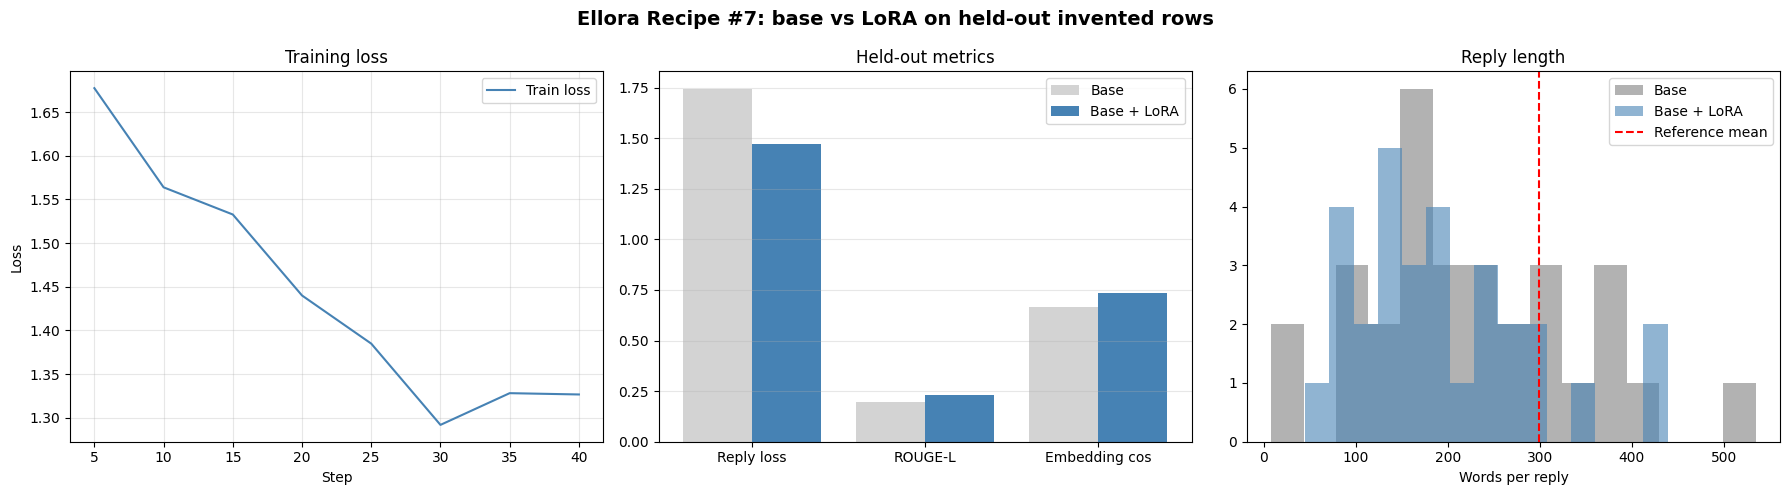

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Ellora Recipe #7: base vs LoRA on held-out invented rows", fontsize=14, fontweight="bold")

if training_metrics["train_loss"]:
    s, l = zip(*training_metrics["train_loss"])
    axes[0].plot(s, l, label="Train loss", color="steelblue")
    axes[0].set_xlabel("Step"); axes[0].set_ylabel("Loss"); axes[0].set_title("Training loss"); axes[0].grid(alpha=0.3); axes[0].legend()

names = ["Reply loss", "ROUGE-L", "Embedding cos"]
keys = ["reply_loss", "rougeL_f1", "embedding_cosine"]
x = np.arange(len(names))
axes[1].bar(x - 0.2, [base_results[k] for k in keys], 0.4, label="Base", color="lightgray")
axes[1].bar(x + 0.2, [lora_results[k] for k in keys], 0.4, label="Base + LoRA", color="steelblue")
axes[1].set_xticks(x); axes[1].set_xticklabels(names); axes[1].set_title("Held-out metrics"); axes[1].legend(); axes[1].grid(alpha=0.3, axis="y")

axes[2].hist([len(p.split()) for p in base_results["predictions"]], bins=15, alpha=0.6, label="Base", color="gray")
axes[2].hist([len(p.split()) for p in lora_results["predictions"]], bins=15, alpha=0.6, label="Base + LoRA", color="steelblue")
axes[2].axvline(ref_words, color="red", linestyle="--", label="Reference mean")
axes[2].set_xlabel("Words per reply"); axes[2].set_title("Reply length"); axes[2].legend()

plt.tight_layout()
plt.savefig("recipe7_results.png", dpi=120, bbox_inches="tight")
plt.show()

## 🔍 Side-by-Side Examples

In [16]:
def show(i: int, width: int = 700):
    r = eval_rows[i]
    print("=" * 100)
    print(f"[{r['area']} | {r['shape']} | {r['difficulty']}]")
    print("PROMPT:", r["prompt"])
    print("\n--- Base model ---\n" + base_results["predictions"][i][:width])
    print("\n--- Base + LoRA ---\n" + lora_results["predictions"][i][:width])
    print("\n--- Reference (DataInventor) ---\n" + r["completion"][:width])
    print(f"\nROUGE-L base {base_results['per_row_rougeL'][i]:.3f} -> LoRA {lora_results['per_row_rougeL'][i]:.3f}")

for i in [0, 1, 2]:
    show(i)

[Administrative Tasks | Follow-up | basic]
PROMPT: Add a template for guiding users on where to update their email preferences in the account settings menu.

--- Base model ---
Certainly! Below is a template you can use to guide users on how to update their email preferences within the account settings menu:

---

**How to Update Email Preferences**

1. **Navigate to Account Settings:**
   - Open your web browser and go to the website or app where you manage your account.
   - Look for an icon that resembles a gear or a person with a house, which typically represents the account settings.

2. **Find the Email Preferences Section:**
   - Once you're in the account settings, look for a section labeled "Email Preferences," "Preferences," or something similar.
   - This section will usually contain options related to receiving notifications, updates, and communications

--- Base + LoRA ---
**Subject: How to Update Your Email Preferences**

Dear [Customer Name],

We understand that your com

## ⚖️ Optional: LLM Judge

Overlap metrics cannot tell whether a reply is *correct* or *safe* (for example, never asking a customer for a full card number or PIN). A judge model can check that. This cell is **skipped by default**; set `RUN_JUDGE = True` and point it at any OpenAI-compatible endpoint. Judges have their own biases, so read a sample of the verdicts yourself.

In [17]:
RUN_JUDGE = False
JUDGE_BASE_URL = os.environ.get("JUDGE_BASE_URL", "https://router.huggingface.co/v1")
JUDGE_MODEL = os.environ.get("JUDGE_MODEL", "openai/gpt-oss-120b")
JUDGE_API_KEY = os.environ.get("JUDGE_API_KEY", "")

JUDGE_PROMPT = '''You are reviewing two replies from a bank's customer support assistant.

Customer message:
{prompt}

Reply A:
{a}

Reply B:
{b}

Which reply is more helpful, accurate and safe for a real bank customer (never asks for a full card number, PIN or password; gives clear next steps)?
Answer with exactly one of: A, B, TIE.'''

if RUN_JUDGE:
    import requests
    votes = {"base": 0, "lora": 0, "tie": 0}
    for i in tqdm(range(len(eval_rows)), desc="Judging"):
        flip = i % 2 == 1   # alternate positions to reduce position bias
        a, b = (lora_results["predictions"][i], base_results["predictions"][i]) if flip else (base_results["predictions"][i], lora_results["predictions"][i])
        resp = requests.post(f"{JUDGE_BASE_URL}/chat/completions", headers={"Authorization": f"Bearer {JUDGE_API_KEY}"}, timeout=120, json={
            "model": JUDGE_MODEL, "temperature": 0, "max_tokens": 1024,
            "messages": [{"role": "user", "content": JUDGE_PROMPT.format(prompt=eval_rows[i]["prompt"], a=a, b=b)}]})
        verdict = resp.json()["choices"][0]["message"]["content"].strip().upper()
        if verdict.startswith("TIE"):
            votes["tie"] += 1
        elif verdict.startswith("A"):
            votes["lora" if flip else "base"] += 1
        elif verdict.startswith("B"):
            votes["base" if flip else "lora"] += 1
    print("Judge votes:", votes)
else:
    print("⏭️ Skipping the LLM judge (set RUN_JUDGE = True and JUDGE_API_KEY to run it)")

⏭️ Skipping the LLM judge (set RUN_JUDGE = True and JUDGE_API_KEY to run it)


## 💾 Save the Trained Adapter

In [18]:
output_dir = CONFIG["output_dir"]
training_model.save_pretrained(output_dir)
tokenizer.save_pretrained(output_dir)

TIMINGS["total_s"] = round(time.time() - T_START, 1)
strip = lambda r: {k: v for k, v in r.items() if k not in ("predictions", "per_row_rougeL", "per_row_cosine")}
report = {
    "config": CONFIG,
    "train_rows": len(train_rows),
    "eval_rows": len(eval_rows),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "base": strip(base_results),
    "lora": strip(lora_results),
    "training_metrics": training_metrics,
    "timings_s": TIMINGS,
}
with open(os.path.join(output_dir, "evaluation_results.json"), "w") as f:
    json.dump(report, f, indent=2)
with open(os.path.join(output_dir, "heldout_predictions.jsonl"), "w") as f:
    for i in range(len(eval_rows)):
        f.write(json.dumps({"prompt": eval_rows[i]["prompt"], "reference": eval_rows[i]["completion"],
                            "base": base_results["predictions"][i], "lora": lora_results["predictions"][i]}, ensure_ascii=False) + "\n")

print(f"✅ Adapter, metrics and held-out predictions saved to: {output_dir}")
print("Timings (s):", TIMINGS)
print(json.dumps({"base": strip(base_results), "lora": strip(lora_results)}, indent=2))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

✅ Adapter, metrics and held-out predictions saved to: ./banking_support_lora
Timings (s): {'load_model_s': 8.8, 'eval_base_s': 98.2, 'train_s': 201.8, 'eval_lora_s': 146.4, 'total_s': 478.0}
{
  "base": {
    "reply_loss": 1.7436969034777867,
    "reply_perplexity": 5.718444932474878,
    "reply_tokens": 12316,
    "rougeL_f1": 0.1964215541902057,
    "embedding_cosine": 0.6681868433952332,
    "avg_words": 224.03333333333333,
    "seconds": 98.2
  },
  "lora": {
    "reply_loss": 1.4699403230692512,
    "reply_perplexity": 4.348975599802807,
    "reply_tokens": 12316,
    "rougeL_f1": 0.23020022874293858,
    "embedding_cosine": 0.7337719798088074,
    "avg_words": 193.9,
    "seconds": 146.4
  }
}


In [19]:
# Reload check: the saved adapter loads onto a fresh base model
reloaded = AutoModelForCausalLM.from_pretrained(CONFIG["model_name"], torch_dtype=DTYPE, cache_dir=CONFIG["cache_dir"]).to(DEVICE)
reloaded = PeftModel.from_pretrained(reloaded, output_dir)
print("✅ Reloaded adapter:", type(reloaded).__name__)
print(generate_replies(reloaded, ["I just got my new credit card in the mail. How do I activate it?"])[0][:600])
del reloaded

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

✅ Reloaded adapter: PeftModelForCausalLM


Generating:   0%|          | 0/1 [00:00<?, ?it/s]

To activate your new credit card, you can follow these steps:

1. **Log In to Your Account:** Log in to your online banking or mobile app account associated with your credit card.
2. **Navigate to Activation:** Look for an "Activate Card" or "Card Activation" option within your account settings. This is usually found under "Manage Cards."
3. **Enter Security Questions:** If prompted, enter the security questions and answers that were sent to your registered email address or phone number.
4. **Scan the QR Code:** If your card arrived with a unique activation code (often printed on the back of t


## 🚀 Optional: Push the Adapter to the Hugging Face Hub

In [20]:
PUSH_TO_HUB = False   # set True after logging in with huggingface_hub.login()
HUB_REPO = "your-username/qwen2.5-1.5b-instruct-banking-support-lora"

if PUSH_TO_HUB:
    from huggingface_hub import login
    login()
    training_model.push_to_hub(HUB_REPO, private=True)
    tokenizer.push_to_hub(HUB_REPO, private=True)
    print(f"✅ Pushed to https://huggingface.co/{HUB_REPO} (private)")
else:
    print("⏭️ Skipping push to the Hub")

⏭️ Skipping push to the Hub


## 🎯 Conclusion

### 📊 Recipe Summary

This notebook demonstrated **Ellora Recipe #7: Zero to Fine-Tuned with an Invented Dataset**: one plain-language request became 200 training rows in DataInventor, and those rows became a LoRA adapter for a 1.5B instruct model in about a quarter of an hour on a free GPU.

#### ✅ What the recipe shows:
1. **Open data invention:** DataInventor's blueprint, sampling, writing and filtering steps produce varied rows from one sentence, with any OpenAI-compatible model.
2. **Small-data LoRA:** 170 rows are enough to move a small model toward the length, structure and tone of the target replies.
3. **Honest held-out evaluation:** the base model and the adapter are scored on the same 30 unseen rows with the same decoding settings.

#### 📈 Results:
The summary table in the Results section above prints the base vs adapter numbers for your run, and `banking_support_lora/evaluation_results.json` keeps them with the timings.

#### ⚠️ Limits:
- The training rows were written by a model and not checked by a person. The adapter learns that model's style, habits and any errors.
- ROUGE-L and embedding similarity measure closeness to the reference replies, not correctness. Use the optional judge, or read the examples, before trusting the adapter with customers.
- 30 held-out rows is a small test set; differences of a point or two are within noise.

#### 🔄 Next steps:
- Invent rows for your own domain with the optional DataInventor cell and re-run.
- Try `format: "preference"` in DataInventor and train with DPO on the chosen / rejected pairs.
- Scale the row count or the base model if the held-out loss is still falling at the end of training.